# CardioSentry — synthetic ECG image generation (Colab)

Generates the full synthetic paper-ECG corpus from the **v3** harmonized signals.

| | |
|---|---|
| input | `datasets/harmonized.tar` (v3 signals) + `datasets/cardiosentry_pipeline.tar.gz` (patched code) |
| output | `experiments/synthetic_images_v1/` (corpus archives) and `runs/synthetic_images_v1/` (index, logs) |
| expected | ~37,225 records -> ~129,376 images, 8-12 h on 12 vCPU |

**The GPU is not used.** Nothing in this pipeline touches CUDA; the L4 runtime is
only a way to get 12 vCPUs. Section 0 disables CUDA so TensorFlow (imported by the
kit but never called) does not waste time initialising it.

**Everything is resumable.** Stages 2-4 skip work already on disk, so a Colab
disconnect costs only the in-flight chunk. Re-run the same cells.

---
## How to use
1. Run **section 1 (preflight)** first. It hard-stops on any problem *before* the
   8-hour job starts. Do not skip it.
2. Run section 2 (smoke test, ~2 min) and eyeball the image.
3. Run section 3 (full build).
4. Run section 4 (package to Drive).


## 0. Runtime setup


In [ ]:
import os, sys, subprocess, time, json, importlib, importlib.util
from pathlib import Path

# Nothing here uses the GPU. Hiding it stops TF from initialising CUDA on every
# one of the ~100 kit invocations, which is pure overhead.
os.environ['CUDA_VISIBLE_DEVICES'] = ''

DRIVE   = Path('/content/drive/MyDrive/CardioSentry')
DATASETS= DRIVE/'datasets'
CODES   = DRIVE/'codes'/'synthetic_image_generation'
EXPDIR  = DRIVE/'experiments'/'synthetic_images_v1'
RUNDIR  = DRIVE/'runs'/'synthetic_images_v1'

WORK    = Path('/content/work')          # LOCAL disk - never build on Drive
CODE    = WORK/'code'
DATA    = WORK/'data'/'releases'/'v3'
BUILD   = WORK/'build'

from google.colab import drive
drive.mount('/content/drive')
print('mounted')


Mounted at /content/drive
mounted


In [ ]:
# Build parameters. Change these BEFORE the preflight, not after.
PARAMS = dict(
    ECG_RELEASE     = 'v3',
    ECG_WORKERS     = str(os.cpu_count() or 12),
    ECG_IMAGE_BUILD = str(BUILD),
    ECGKIT_DIR      = str(CODE/'ecg-image-kit'),
    ECGKIT_PY       = sys.executable,
    ECG_ANNOTATIONS = '1',   # '0' saves ~45 GB and ~10% time; drop only if you will
                             # never do segmentation / digitisation work
    # Deliberately NOT set, so the config defaults apply:
    #   ECG_LOWPASS_HZ  -> 0.05-40 Hz (paired with 150 DPI; see config.py)
    #   ECG_PRINT_HEADER-> off (no ID/Name/Date/Age/Sex)
    #   ECG_ROW_GAP     -> 4.4   ECG_RHYTHM_GAP -> 5.5
    #   ECG_DPI         -> 150
)
os.environ.update(PARAMS)
for k, v in PARAMS.items(): print(f'{k:18s} {v}')


ECG_RELEASE        v3
ECG_WORKERS        12
ECG_IMAGE_BUILD    /content/work/build
ECGKIT_DIR         /content/work/code/ecg-image-kit
ECGKIT_PY          /usr/bin/python3
ECG_ANNOTATIONS    1


## 1. Preflight

Every check below hard-stops the notebook. The point is to fail in the first two
minutes rather than eight hours in.


In [ ]:
FAIL = []
def check(name, ok, detail=''):
    print(('  OK   ' if ok else '  FAIL ') + name + (f'  -- {detail}' if detail else ''))
    if not ok: FAIL.append(name)

def die():
    """Stop the notebook if anything in this section failed."""
    if FAIL:
        msg = 'PREFLIGHT FAILED:\n  - ' + '\n  - '.join(FAIL)
        FAIL.clear()          # so a re-run after a fix starts clean
        raise SystemExit(msg)
    print('  -> section OK')

def section(title):
    FAIL.clear()              # each section judges only its own checks
    print(title)

section('[1] Drive layout')
for p in (DRIVE, DATASETS):
    check(f'{p} exists', p.is_dir())
for p in (CODES, EXPDIR, RUNDIR):
    p.mkdir(parents=True, exist_ok=True)
    check(f'{p.relative_to(DRIVE)} writable', os.access(p, os.W_OK))
die()


[1] Drive layout
  OK   /content/drive/MyDrive/CardioSentry exists
  OK   /content/drive/MyDrive/CardioSentry/datasets exists
  OK   codes/synthetic_image_generation writable
  OK   experiments/synthetic_images_v1 writable
  OK   runs/synthetic_images_v1 writable
  -> section OK


In [ ]:
section('[2] Input archives present in datasets/')
SIG_TAR  = DATASETS/'harmonized.tar'
CODE_TAR = DATASETS/'cardiosentry_pipeline.tar.gz'
check('harmonized.tar', SIG_TAR.is_file(), f'{SIG_TAR.stat().st_size/2**30:.2f} GB' if SIG_TAR.is_file() else 'missing')
check('cardiosentry_pipeline.tar.gz', CODE_TAR.is_file(),
      f'{CODE_TAR.stat().st_size/2**20:.0f} MB' if CODE_TAR.is_file() else 'upload it to datasets/')
die()


[2] Input archives present in datasets/
  OK   harmonized.tar  -- 4.31 GB
  OK   cardiosentry_pipeline.tar.gz  -- 12 MB
  -> section OK


In [ ]:
section('[3] Local disk and RAM')
st = os.statvfs('/content')
free_gb = st.f_bavail*st.f_frsize/2**30
need = 4.5 + (131.1 if os.environ['ECG_ANNOTATIONS']=='1' else 86.1)
check(f'free disk {free_gb:.0f} GB >= {need:.0f} GB needed', free_gb >= need,
      'set ECG_ANNOTATIONS=0 to need ~91 GB' if free_gb < need else '')
ram = os.sysconf('SC_PAGE_SIZE')*os.sysconf('SC_PHYS_PAGES')/2**30
check(f'RAM {ram:.0f} GB', ram >= 8)
check(f'vCPUs {os.cpu_count()}', (os.cpu_count() or 0) >= 4)
die()


[3] Local disk and RAM
  OK   free disk 188 GB >= 136 GB needed
  OK   RAM 53 GB
  OK   vCPUs 12
  -> section OK


In [ ]:
section('[4] Extract code + signals to LOCAL disk')
# Reading 74,662 signal files through the Drive FUSE layer would take hours.
# Extract once to /content and never touch Drive again until packaging.
def untar(archive, dest, flag):
    dest.mkdir(parents=True, exist_ok=True)
    r = subprocess.run(['tar', flag, str(archive), '-C', str(dest)],
                       capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1500:]); raise SystemExit(f'failed to extract {archive.name}')

CODE = WORK/'code'
if not (CODE/'image_pipeline'/'config.py').exists():
    untar(CODE_TAR, CODE, '-xzf')
if not (DATA/'harmonized'/'harmonized_ecg_metadata.csv').exists():
    untar(SIG_TAR, DATA, '-xf')

PIPE = CODE/'image_pipeline'
CSV  = DATA/'harmonized'/'harmonized_ecg_metadata.csv'

# Optional CSV override. The metadata CSV changes far more often than the 4.4 GB
# of signals it describes - freezing the train/val/test split rewrites it, for
# one. Dropping the newer CSV into datasets/ avoids re-uploading the whole tar.
CSV_OVERRIDE = DATASETS/'harmonized_ecg_metadata.csv'
if CSV_OVERRIDE.is_file():
    import shutil
    shutil.copy2(CSV_OVERRIDE, CSV)
    print(f'  using CSV override from datasets/ ({CSV_OVERRIDE.stat().st_size/2**20:.0f} MB)')

check('image_pipeline/config.py', (PIPE/'config.py').is_file())
check('harmonized_ecg_metadata.csv', CSV.is_file())
sigdir = DATA/'harmonized'/'signals'
n_sig = len(list(sigdir.rglob('*.hea'))) if sigdir.is_dir() else 0
check(f'signal headers found: {n_sig:,}', n_sig > 30000, 'expected ~37,329')

# The frozen split. stage 1 REFUSES to invent one, by design: the split is a
# property of the dataset, so a build must never silently reassign it. If this
# fails, run  python scripts/freeze_splits.py --release v3  on the source
# release and put the resulting CSV in datasets/ as harmonized_ecg_metadata.csv.
import pandas as _pd
_h = _pd.read_csv(CSV, nrows=5)
has_split = 'split' in _h.columns
check('CSV has a split column', has_split,
      'run scripts/freeze_splits.py --release v3, then drop the CSV into datasets/')
if has_split:
    _s = _pd.read_csv(CSV, usecols=['split'])
    vc = _s.split.value_counts(dropna=False)
    print('   ', dict(vc))
    check('split is fully populated', _s.split.notna().all() and (_s.split != '').all())
    check('all three folds present', set(vc.index) >= {'train','val','test'})
die()


[4] Extract code + signals to LOCAL disk
  using CSV override from datasets/ (44 MB)
  OK   image_pipeline/config.py
  OK   harmonized_ecg_metadata.csv
  OK   signal headers found: 37,329  -- expected ~37,329
  OK   CSV has a split column  -- run scripts/freeze_splits.py --release v3, then drop the CSV into datasets/
    {'train': np.int64(30555), 'val': np.int64(3439), 'test': np.int64(3335)}
  OK   split is fully populated
  OK   all three folds present
  -> section OK


In [ ]:
section('[5] Python dependencies')
import importlib, importlib.util

# This list was derived EMPIRICALLY, by blocking each candidate and re-running
# a real render until it broke. It is not the kit's requirements.txt, which
# pins tensorflow, spacy, seaborn, keras, imutils, validators, bs4 and
# scikit-learn - all of which patch_kit.py's lazy-deps patch removes from the
# import path, because the helpers that need them are gated behind flags this
# pipeline never sets.
#
# imgaug itself hard-requires cv2 and skimage; both are Colab preinstalls.
MODS = ('numpy','scipy','pandas','wfdb','PIL','matplotlib',
        'imgaug','cv2','skimage','qrcode','imageio','yaml')
PIP  = {'PIL':'pillow','cv2':'opencv-python','skimage':'scikit-image',
        'yaml':'pyyaml','imgaug':'imgaug','wfdb':'wfdb','qrcode':'qrcode',
        'imageio':'imageio'}

missing = [m for m in MODS if not importlib.util.find_spec(m)]
if missing:
    pkgs = sorted({PIP.get(m, m) for m in missing})
    print('  installing:', pkgs)
    subprocess.run([sys.executable,'-m','pip','-q','install',*pkgs], check=False)
    importlib.invalidate_caches()

# numpy 2 removed np.sctypes; imgaug 0.4.0 reads it at module level. The kit's
# entry point carries the same shim (patch_kit.py) - this copy only lets the
# notebook process import imgaug to verify it is installed.
import numpy as _np
if not hasattr(_np, 'sctypes'):
    _np.sctypes = {
        'int':     [_np.int8, _np.int16, _np.int32, _np.int64],
        'uint':    [_np.uint8, _np.uint16, _np.uint32, _np.uint64],
        'float':   [_np.float16, _np.float32, _np.float64],
        'complex': [_np.complex64, _np.complex128],
        'others':  [bool, object, bytes, str, _np.void],
    }
    print(f'  applied np.sctypes shim (numpy {_np.__version__})')
print(f'  numpy {_np.__version__}')

# IMPORT each one. find_spec only proves a module EXISTS and never executes it,
# which is exactly how imgaug/numpy-2 and the missing `validators` both passed
# preflight and then killed every render two minutes later.
for m in MODS:
    try:
        importlib.import_module(m)
        check(m, True)
    except Exception as e:
        check(m, False, f'{type(e).__name__}: {e}')
die()


[5] Python dependencies
  installing: ['imgaug', 'qrcode', 'wfdb']
  applied np.sctypes shim (numpy 2.1.3)
  numpy 2.1.3
  OK   numpy
  OK   scipy
  OK   pandas
  OK   wfdb
  OK   PIL
  OK   matplotlib
  OK   imgaug
  OK   cv2
  OK   skimage
  OK   qrcode
  OK   imageio
  OK   yaml
  -> section OK


In [ ]:
section('[6] Kit patches — the build is WRONG without these')
sys.path.insert(0, str(PIPE))
os.chdir(PIPE)
for m in list(sys.modules):
    if m in ('config','patch_kit'): del sys.modules[m]
import config as C, patch_kit
print(subprocess.run([sys.executable,'patch_kit.py'],capture_output=True,text=True).stdout)
importlib.reload(patch_kit)
check('all kit patches applied', patch_kit.is_patched(),
      'patch_kit reported FAILED above -- do not proceed')
die()


[6] Kit patches — the build is WRONG without these
ecg_plot.py: header        already patched
ecg_plot.py: lead names    already at 1.15
ecg_plot.py: rhythm strip  already at 1.15
ecg_plot.py: ink width     already patched
ecg_plot.py: layout        already patched
ecg_plot.py: paper size    already patched
extract_leads.py: columns   already patched
gen_ecg_images_from_data_batch.py: numpy2 shim  already patched
gen_ecg_image_from_data.py: lazy deps  already patched

  OK   all kit patches applied  -- patch_kit reported FAILED above -- do not proceed
  -> section OK


In [ ]:
section('[7] Effective settings — read these carefully')
importlib.reload(C)
print(f'  band-pass       {C.BANDPASS[0]}-{C.BANDPASS[1]} Hz')
print(f'  printed header  {C.PRINT_HEADER}')
print(f'  annotations     {C.ANNOTATIONS}')
print(f'  DPI             {C.DPI}')
print(f'  row / rhythm gap{C.ROW_GAP} / {C.RHYTHM_GAP}  (x10 mm)')
print(f'  workers         {C.WORKERS}')
print(f'  variants        {C.VARIANTS_PER_SPLIT}')
check('band-pass is 0.05-40 Hz', C.BANDPASS == (0.05, 40.0),
      'the 40 Hz band is PAIRED with 150 DPI: image Nyquist is 73.8 Hz, and a\n       wider band renders mains hum concentrated in CUHK, the only source of\n       STEMI co-morbidity')
check('printed header is OFF', C.PRINT_HEADER is False,
      'ON would drop ~17,875 age-less records and zero the STEMI+AF+LVH class')
_f = C.KIT_RENDER_FLAGS
_ncol = _f[_f.index('--num_columns')+1] if '--num_columns' in _f else None
check(f'4 leads per row (got {_ncol})', _ncol == '4',
      'more columns shortens each panel: 10 s is split across them')
die()

# Probe the KIT's own import chain in a subprocess, exactly as stage 3 runs it.
# This is what proves the numpy-2 shim is in place before anything long starts.
probe = subprocess.run([sys.executable, '-c',
    'import gen_ecg_images_from_data_batch as m; print("kit entry point OK")'],
    cwd=C.KIT, capture_output=True, text=True,
    env={**os.environ, 'TF_CPP_MIN_LOG_LEVEL': '3'})
check('kit entry point imports (numpy-2 shim works)', probe.returncode == 0,
      probe.stderr.strip().splitlines()[-1] if probe.returncode else '')
die()


[7] Effective settings — read these carefully
  band-pass       0.05-40.0 Hz
  printed header  False
  annotations     True
  DPI             150
  row / rhythm gap4.4 / 5.5  (x10 mm)
  workers         12
  variants        {'train': 4, 'val': 1, 'test': 1}
  OK   band-pass is 0.05-40 Hz  -- the 40 Hz band is PAIRED with 150 DPI: image Nyquist is 73.8 Hz, and a
       wider band renders mains hum concentrated in CUHK, the only source of
       STEMI co-morbidity
  OK   printed header is OFF  -- ON would drop ~17,875 age-less records and zero the STEMI+AF+LVH class
  OK   4 leads per row (got 4)  -- more columns shortens each panel: 10 s is split across them
  -> section OK
  OK   kit entry point imports (numpy-2 shim works)
  -> section OK


## 2. Smoke test (~2 min)

Renders 5 records that have **no recorded age**, including the triple-positive
class. This is the specific case that two separate bugs used to drop silently, so
it is the one worth proving before an 8-hour run.


In [ ]:
import pandas as pd
SMOKE = WORK/'smoke'; SMOKE.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(CSV, low_memory=False)
here = CSV.parent
noage = df[df.age.isna() & (df.validation_status=='VALID')]
picks = [noage[noage.cardiosentry_label==l].iloc[0]
         for l in ('STEMI+AF+LVH','STEMI+LVH','STEMI+AF','AF+LVH','LVH')
         if len(noage[noage.cardiosentry_label==l])]
sub = pd.DataFrame(picks).copy()
for c in ('signal_path','header_path','data_path'):
    sub[c] = sub[c].map(lambda p: str((here/p).resolve()))
sub['split'] = 'test'
sub.to_csv(SMOKE/'smoke.csv', index=False)
print(sub[['global_record_id','source_dataset','cardiosentry_label','age','sex']].to_string(index=False))


global_record_id source_dataset cardiosentry_label  age     sex
     CUHK_000485           CUHK       STEMI+AF+LVH  NaN    Male
     CUHK_000040           CUHK          STEMI+LVH  NaN    Male
     CUHK_000146           CUHK           STEMI+AF  NaN Unknown
     CUHK_000027           CUHK             AF+LVH  NaN  Female
  CHAPMAN_014050        CHAPMAN                LVH  NaN    Male


In [ ]:
LOGS = WORK/'logs'; LOGS.mkdir(parents=True, exist_ok=True)

def run(script, *args, env=None, quiet=False, tag=None):
    """Run a pipeline stage, STREAMING its output live and teeing it to a log.

    Not subprocess.run(capture_output=True): that buffers everything until the
    process exits, so a 5-8 hour stage 3 would show nothing at all until it was
    over. Popen + line iteration prints progress as it happens, and -u stops
    Python block-buffering its stdout when writing to a pipe instead of a tty.

    Every line also lands in WORK/logs/<stage>.log, so the Colab terminal can
        tail -f /content/work/logs/stage3.log
    and watch the same output from outside the notebook.
    """
    name = tag or script.replace('.py','')
    log  = LOGS/f'{name}.log'
    cmd  = [sys.executable, '-u', script, *args]
    started = time.time()
    lines = []
    with open(log, 'w') as fh:
        proc = subprocess.Popen(cmd, cwd=PIPE, env={**os.environ, **(env or {})},
                                stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                text=True, bufsize=1)
        for line in proc.stdout:
            fh.write(line); fh.flush()
            lines.append(line)
            if not quiet:
                print(line, end='', flush=True)
        proc.wait()
    out = ''.join(lines).strip()
    mins = (time.time()-started)/60
    print(f'  [{name}] finished in {mins:.1f} min  ->  {log}')
    if proc.returncode:
        print(out[-2000:]); raise SystemExit(f'{script} failed (see {log})')
    return out

SMOKE_ENV = {'ECG_IMAGE_BUILD': str(SMOKE/'build')}
W = os.environ['ECG_WORKERS']
run('stage1_manifest_from_csv.py', '--input-csv', str(SMOKE/'smoke.csv'),
    env=SMOKE_ENV, tag='smoke_stage1')
run('stage2_transcode.py', env=SMOKE_ENV, tag='smoke_stage2')
run('stage3_render.py', '-j', W, env=SMOKE_ENV, tag='smoke_stage3')
run('stage4_augment.py', '-j', W, env=SMOKE_ENV, tag='smoke_stage4')


reading 5 rows from /content/work/smoke/smoke.csv
using the split column already FROZEN in the CSV (scripts/freeze_splits.py) - not recomputing it

manifest: 5 records -> /content/work/smoke/build/image_manifest.csv

    class        train    val   test    recs   images
    AF+LVH           0      0      1       1        1
    LVH              0      0      1       1        1
    STEMI+AF         0      0      1       1        1
    STEMI+AF+LVH       0      0      1       1        1
    STEMI+LVH        0      0      1       1        1
    TOTAL                                  5        5

    images per split (variants: train=4, val=1, test=1):
      train        0 records x 4 =        0 images
      val          0 records x 1 =        0 images   <- exactly one per ECG
      test         5 records x 1 =        5 images   <- exactly one per ECG

    by source: CHAPMAN=1, CUHK=4
    Reminder: STEMI is single-source. Whatever the leakage probe in
    stage 5 says, report per-source metr

'5 images on 12 workers\n/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: \'mode\' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)\n  return Image.fromarray(lut[grey].astype(np.uint8), "RGB"), name\n/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: \'mode\' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)\n  return Image.fromarray(lut[grey].astype(np.uint8), "RGB"), name\n/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: \'mode\' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)\n  return Image.fromarray(lut[grey].astype(np.uint8), "RGB"), name\n/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: \'mode\' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)\n  return Image.fromarray(lut[grey].astype(np.uint8), "RGB"), name\n/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: \'

[smoke] verify
  OK   5 images produced (got 5)  -- fewer means records are still being dropped
  OK   clean renders exist
  OK   no header text on the sheet  -- darkest pixel 102; text would be <70
  -> section OK


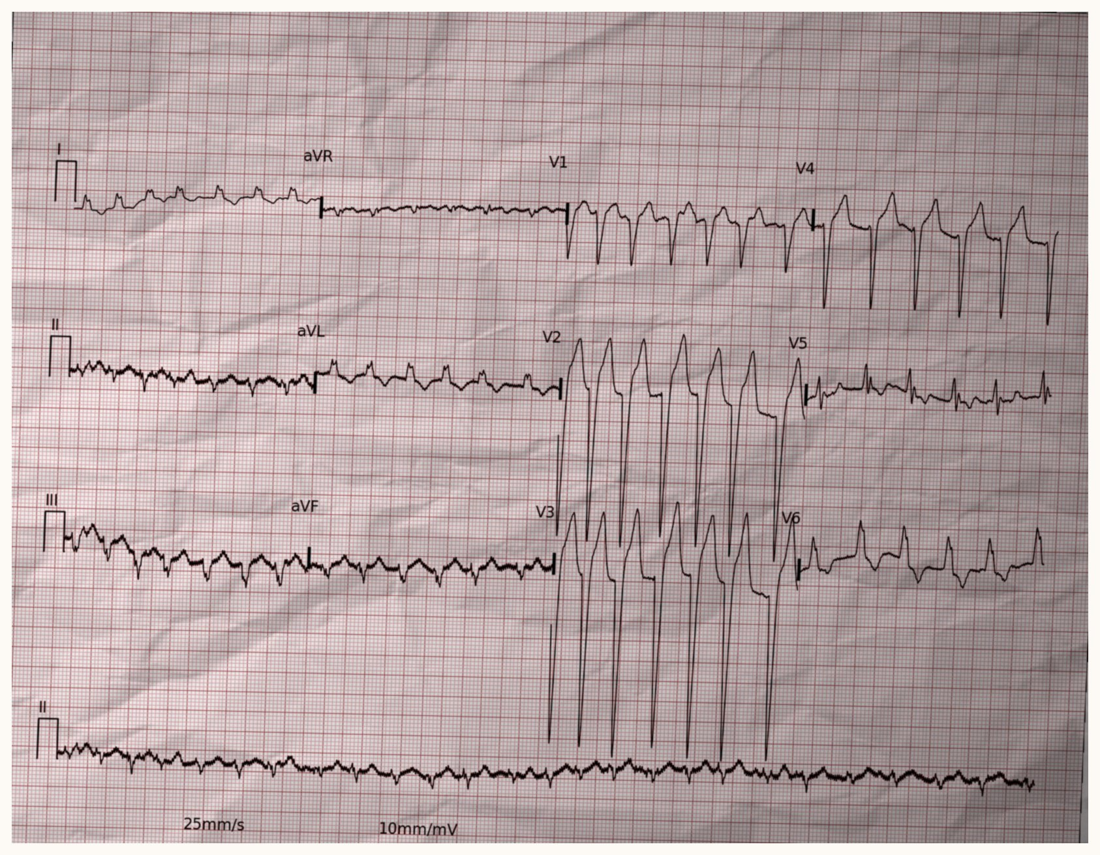

In [ ]:
section('[smoke] verify')
imgs = sorted((SMOKE/'build'/'images').rglob('*.jpg'))
check(f'5 images produced (got {len(imgs)})', len(imgs) == 5,
      'fewer means records are still being dropped')

import numpy as np
from PIL import Image as PILImage
ppmm = C.DPI/25.4
pngs = sorted((SMOKE/'build'/'rendered').rglob('*.png'))
check('clean renders exist', len(pngs) > 0)
if pngs:
    g = np.asarray(PILImage.open(pngs[0]).convert('L'), float)
    band = g[int(14*ppmm):int(30*ppmm), int(15*ppmm):int(95*ppmm)]
    check('no header text on the sheet', band.min() >= 95,
          f'darkest pixel {band.min():.0f}; text would be <70')
die()

im = PILImage.open(imgs[0])
display(im.resize((1100, int(1100*im.height/im.width))))


## 3. Full build (8-12 h)

Safe to re-run after a disconnect — every stage skips finished work.

Stage 1 prints the record count and split. **Sanity-check it before letting
stage 3 start:** you want ~37,225 records and a `STEMI+AF+LVH` row that is not zero.


In [ ]:
# Full build. run() now reads os.environ at call time, so ECG_IMAGE_BUILD is
# BUILD (set in section 0), not the smoke directory.
assert os.environ['ECG_IMAGE_BUILD'] == str(BUILD), os.environ['ECG_IMAGE_BUILD']
t0 = time.time()
out1 = run('stage1_manifest_from_csv.py', '--input-csv', str(CSV))


reading 37329 rows from /content/work/data/releases/v3/harmonized/harmonized_ecg_metadata.csv
using the split column already FROZEN in the CSV (scripts/freeze_splits.py) - not recomputing it

manifest: 37225 records -> /content/work/build/image_manifest.csv
skipped:
    skip_validation_CHECK           104

    class        train    val   test    recs   images
    AF            6822    782    688    8292    28758
    AF+LVH        2010    163    203    2376     8406
    LVH           8126    821    752    9699    34077
    NORMAL       10233   1280   1326   12839    43538
    STEMI         2763    311    328    3402    11691
    STEMI+AF       138     18     17     173      587
    STEMI+AF+LVH      38      5      0      43      157
    STEMI+LVH      331     54     16     401     1394
    TOTAL                              37225   128608

    images per split (variants: train=4, val=1, test=1):
      train    30461 records x 4 =   121844 images
      val       3434 records x 1 =     34

In [ ]:
section('[gate] manifest sanity')
# Refuse to burn 8 hours on a manifest that lost the multi-label classes.
man = pd.read_csv(BUILD/'image_manifest.csv')
counts = man.cls.value_counts()
print(counts.to_string()); print(f'\ntotal {len(man):,}')
check(f'record count {len(man):,} >= 35,000', len(man) >= 35000)
check(f"STEMI+AF+LVH present ({counts.get('STEMI+AF+LVH',0)})", counts.get('STEMI+AF+LVH',0) > 0)
check(f"AF+LVH >= 2,000 ({counts.get('AF+LVH',0)})", counts.get('AF+LVH',0) >= 2000)
die()


[gate] manifest sanity
cls
NORMAL          12839
LVH              9699
AF               8292
STEMI            3402
AF+LVH           2376
STEMI+LVH         401
STEMI+AF          173
STEMI+AF+LVH       43

total 37,225
  OK   record count 37,225 >= 35,000
  OK   STEMI+AF+LVH present (43)
  OK   AF+LVH >= 2,000 (2376)
  -> section OK


In [ ]:
section('[gate] stage 2')
out2 = run('stage2_transcode.py')
# Assert against config, not a hardcoded string: hardcoding the band is what
# left a stale '0.05-150 Hz' check here after the default was changed.
_band = f'{C.BANDPASS[0]:g}-{C.BANDPASS[1]:g} Hz'
check(f'stage 2 used the configured band ({_band})', _band in out2,
      out2.splitlines()[0] if out2 else 'no output')
check('no records lost to missing_metadata', 'missing_metadata' not in out2)
die()


[gate] stage 2
band-pass: 0.05-40 Hz, zero-phase 2nd-order Butterworth (40 Hz from config default)
  1000/37225
  2000/37225
  3000/37225
  4000/37225
  5000/37225
  6000/37225
  7000/37225
  8000/37225
  9000/37225
  10000/37225
  11000/37225
  12000/37225
  13000/37225
  14000/37225
  15000/37225
  16000/37225
  17000/37225
  18000/37225
  19000/37225
  20000/37225
  21000/37225
  22000/37225
  23000/37225
  24000/37225
  25000/37225
  26000/37225
  27000/37225
  28000/37225
  29000/37225
  30000/37225
  31000/37225
  32000/37225
  33000/37225
  34000/37225
  35000/37225
  36000/37225
  37000/37225

staged 37225 of 37225 records -> /content/work/build/staged
    ok_AF                    8292
    ok_AF+LVH                2376
    ok_LVH                   9699
    ok_NORMAL               12839
    ok_STEMI                 3402
    ok_STEMI+AF               173
    ok_STEMI+AF+LVH            43
    ok_STEMI+LVH              401
wrote /content/work/build/staged_map.csv
  [stage2_transcod

In [ ]:
# The long one, ~5-8 h. Safe to re-run after a disconnect.
out3 = run('stage3_render.py', '-j', os.environ['ECG_WORKERS'])
print(f'elapsed so far: {(time.time()-t0)/3600:.1f} h')


98 render jobs on 12 workers
  [1/98] AF/c007/r0: 400 images  (eta 2220 min)
  [2/98] AF/c000/r0: 400 images  (eta 1100 min)
  [3/98] AF/c005/r0: 400 images  (eta 727 min)
  [4/98] AF/c001/r0: 400 images  (eta 540 min)
  [5/98] AF/c011/r0: 400 images  (eta 428 min)
  [6/98] AF/c003/r0: 400 images  (eta 353 min)
  [7/98] AF/c009/r0: 400 images  (eta 300 min)
  [8/98] AF/c004/r0: 400 images  (eta 260 min)
  [9/98] AF/c002/r0: 400 images  (eta 229 min)
  [10/98] AF/c006/r0: 400 images  (eta 204 min)
  [11/98] AF/c010/r0: 400 images  (eta 183 min)
  [12/98] AF/c008/r0: 400 images  (eta 166 min)
  [13/98] AF/c020/r0: 292 images  (eta 261 min)
  [14/98] AF/c014/r0: 400 images  (eta 276 min)
  [15/98] AF/c013/r0: 400 images  (eta 254 min)
  [16/98] AF/c019/r0: 400 images  (eta 236 min)
  [17/98] AF/c018/r0: 400 images  (eta 220 min)
  [18/98] AF/c015/r0: 400 images  (eta 205 min)
  [19/98] AF/c016/r0: 400 images  (eta 192 min)
  [20/98] AF_LVH/c001/r0: 400 images  (eta 180 min)
  [21/98] AF/c

### Checkpoint after stage 3 — read this

Everything so far lives on `/content`, which is **ephemeral**. Reconnecting to the
same runtime keeps it; a *terminated* runtime wipes it. Stage 3 is the 5-8 hour
part of the job, so it is worth 9 GB and ~15 min of upload to make it survivable.

If the runtime is lost later, run the restore cell instead of re-rendering.


In [ ]:
CHECKPOINT = True     # set False to skip (you are then betting 5-8 h on the VM)

CKPT = EXPDIR/'checkpoint_rendered.tar'
if CHECKPOINT and not CKPT.exists():
    EXPDIR.mkdir(parents=True, exist_ok=True)
    sz = sum(f.stat().st_size for f in (BUILD/'rendered').rglob('*') if f.is_file())
    print(f'archiving {sz/2**30:.1f} GB of clean renders to Drive ...', flush=True)
    r = subprocess.run(['tar','-cf',str(CKPT),'-C',str(BUILD),
                        'rendered','image_manifest.csv','staged_map.csv'],
                       capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1500:]); raise SystemExit('checkpoint failed')
    print(f'  {CKPT.name}  {CKPT.stat().st_size/2**30:.1f} GB')
else:
    print('checkpoint skipped or already present')


archiving 77.4 GB of clean renders to Drive ...
  checkpoint_rendered.tar  77.5 GB


In [ ]:
# RESTORE — only if the runtime was lost after stage 3. Re-run sections 0-1
# first (they re-extract the code and signals), then this, then stage 4.
RESTORE = False
if RESTORE:
    assert CKPT.exists(), f'no checkpoint at {CKPT}'
    BUILD.mkdir(parents=True, exist_ok=True)
    r = subprocess.run(['tar','-xf',str(CKPT),'-C',str(BUILD)],
                       capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1500:]); raise SystemExit('restore failed')
    n = len(list((BUILD/'rendered').rglob('*.png')))
    print(f'restored {n:,} clean renders - stage 4 will pick up from here')


In [ ]:
import os, shutil
def free_gb():
    s = os.statvfs('/content'); return s.f_bavail*s.f_frsize/2**30
print(f'free before {free_gb():.1f} GB')
shutil.rmtree(DATA/'harmonized', ignore_errors=True)   # stage 2 only, done
shutil.rmtree(BUILD/'staged',    ignore_errors=True)   # stage 3 only, done
shutil.rmtree(WORK/'smoke',      ignore_errors=True)
print(f'free after  {free_gb():.1f} GB')

from google.colab import drive          # release the FUSE spool of the 77 GB tar
drive.flush_and_unmount(); drive.mount('/content/drive')
print(f'free after unmount {free_gb():.1f} GB')
!du -sh /content/work/* /root/.cache 2>/dev/null | sort -h

free before 0.0 GB
free after  8.9 GB
Mounted at /content/drive
free after unmount 8.9 GB
12K	/content/work/data
40K	/content/work/logs
14M	/content/work/code
57M	/root/.cache
180G	/content/work/build


In [ ]:
import os
from pathlib import Path
def tally(root, exts):
    out = {e: [0, 0] for e in exts}
    for p in Path(root).rglob('*'):
        e = p.suffix.lower()
        if e in out and p.is_file():
            out[e][0] += 1; out[e][1] += p.stat().st_size
    return out

for name, root in (('rendered', BUILD/'rendered'), ('images', BUILD/'images')):
    if not root.exists():
        print(f'{name}: absent'); continue
    t = tally(root, ('.png', '.jpg', '.json'))
    print(f'{name}:')
    for e, (n, sz) in t.items():
        if n: print(f'   {e:5s} {n:8,d}   {sz/2**30:7.1f} GB   avg {sz/n/1024:6.0f} KB')

print()
print('other in build/:')
for p in sorted((BUILD).iterdir()):
    if p.name not in ('rendered', 'images'):
        print(f'   {p.name}  {p.stat().st_size/2**20:.1f} MB' if p.is_file() else f'   {p.name}/')
s = os.statvfs('/content'); print(f'\nfree {s.f_bavail*s.f_frsize/2**30:.1f} GB')

rendered:
   .png    37,225       8.6 GB   avg    243 KB
   .json   37,225      64.5 GB   avg   1818 KB
images:
   .jpg   108,899      63.3 GB   avg    610 KB
   .json  108,899      37.9 GB   avg    365 KB

other in build/:
   image_manifest.csv  5.5 MB
   index.csv  0.0 MB
   staged_map.csv  3.9 MB

free 8.9 GB


In [ ]:
import sys, os
from pathlib import Path
from collections import defaultdict
sys.path.insert(0, str(PIPE)); os.chdir(PIPE)
import stage4_augment as S4

jobs = S4._plan()
dsts, srcs = defaultdict(list), {}
for j in jobs:
    dsts[j['record']].append(Path(j['dst'])); srcs[j['record']] = Path(j['src'])
print(f'{len(jobs):,} images planned over {len(dsts):,} records')
assert len(jobs) > 120_000, 'plan is short - stop, index.csv would be incomplete'

# A record is safe to reap only when every one of its variants has BOTH the jpg
# and the corpus sidecar. augment() saves the jpg first and the json after
# (:453-468), so a jpg alone means the render annotation may still be in use.
done = [r for r in dsts
        if all(p.exists() and p.with_suffix('.json').exists() for p in dsts[r])]
print(f'{len(done):,} of {len(dsts):,} records fully finished')

freed = 0
for r in done:
    jp = srcs[r].with_suffix('.json')
    if jp.exists():
        freed += jp.stat().st_size; jp.unlink()
print(f'reaped {freed/2**30:.1f} GB  ->  free {free_gb():.1f} GB')

left = sum(1 for j in jobs if not Path(j['dst']).exists())
need = left * 975 / 2**20
print(f'{left:,} images left, need ~{need:.1f} GB, have {free_gb():.1f} GB '
      f'-> {"OK" if free_gb() > need*1.3 else "STILL SHORT, stop and tell me"}')

128,608 images planned over 37,225 records
31,388 of 37,225 records fully finished
reaped 54.4 GB  ->  free 63.4 GB
19,709 images left, need ~18.3 GB, have 63.4 GB -> OK


In [ ]:
import threading
stop, freed2 = threading.Event(), [0, 0]

def reap():
    pending = {r for r in dsts if srcs[r].with_suffix('.json').exists()}
    while pending and not stop.is_set():
        for rec in list(pending):
            if all(p.exists() and p.with_suffix('.json').exists() for p in dsts[rec]):
                jp = srcs[rec].with_suffix('.json')
                if jp.exists():
                    freed2[0] += jp.stat().st_size; freed2[1] += 1; jp.unlink()
                pending.discard(rec)
        stop.wait(60)

threading.Thread(target=reap, daemon=True).start()
out4 = run('stage4_augment.py', '-j', os.environ['ECG_WORKERS'])
stop.set()
print(f'reaped {freed2[1]:,} more, {freed2[0]/2**30:.1f} GB;  free {free_gb():.1f} GB')
print(f'TOTAL elapsed: {(time.time()-t0)/3600:.1f} h')

128608 images on 12 workers
  2000/128608
  4000/128608
  6000/128608
  8000/128608
  10000/128608
  12000/128608
  14000/128608
  16000/128608
  18000/128608
  20000/128608
  22000/128608
  24000/128608
  26000/128608
  28000/128608
  30000/128608
  32000/128608
  34000/128608
  36000/128608
  38000/128608
  40000/128608
  42000/128608
  44000/128608
  46000/128608
  48000/128608
  50000/128608
  52000/128608
  54000/128608
  56000/128608
  58000/128608
  60000/128608
  62000/128608
  64000/128608
  66000/128608
  68000/128608
  70000/128608
  72000/128608
  74000/128608
  76000/128608
  78000/128608
  80000/128608
  82000/128608
  84000/128608
  86000/128608
  88000/128608
  90000/128608
  92000/128608
  94000/128608
  96000/128608
  98000/128608
  100000/128608
  102000/128608
  104000/128608
  106000/128608
  108000/128608
/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  retur

In [ ]:
import pandas as pd
idx = pd.read_csv(BUILD/'index.csv')
n_side = sum(1 for _ in (BUILD/'images').rglob('*.json'))
print(f'rows {len(idx):,}   has_annotation=1 {int(idx.has_annotation.sum()):,}   sidecars on disk {n_side:,}')
print(f'missing annotations: {int((idx.has_annotation==0).sum()):,}')
print()
print(idx.groupby('split').size().to_string())
print()
print(idx.groupby('cls').size().to_string())
print(f"\nSTEMI+AF+LVH: {(idx.cls=='STEMI+AF+LVH').sum()}")

rows 128,608   has_annotation=1 128,607   sidecars on disk 128,607
missing annotations: 1

split
test       3330
train    121844
val        3434

cls
AF              28758
AF+LVH           8406
LVH             34077
NORMAL          43538
STEMI           11691
STEMI+AF          587
STEMI+AF+LVH      157
STEMI+LVH        1394

STEMI+AF+LVH: 157


In [ ]:

bad = idx[idx.has_annotation == 0]
print('--- the 6 ---')
for _, r in bad.iterrows():
    p = Path(r.image_path); s = p.with_suffix('.json')
    try:
        json.loads(s.read_text()); why = 'parses fine (?)'
    except Exception as e:
        why = f'{type(e).__name__} @ {s.stat().st_size:,} B'
    print(f'  {p.name:28s} jpg {p.stat().st_size:>9,} B   json {why}')

print('\n--- scanning all JPEGs for a truncated tail ---')
bad_jpg = []
for p in (BUILD/'images').rglob('*.jpg'):
    with open(p, 'rb') as fh:
        fh.seek(-2, 2)
        if fh.read(2) != b'\xff\xd9':
            bad_jpg.append(p)
print(f'{len(bad_jpg)} truncated JPEG(s)')
for p in bad_jpg[:20]: print('   ', p)

--- the 6 ---
  ECG033029_a0.jpg             jpg   569,344 B   json JSONDecodeError @ 0 B
  ECG033029_a1.jpg             jpg   774,106 B   json JSONDecodeError @ 299,008 B
  ECG033029_a2.jpg             jpg   460,942 B   json JSONDecodeError @ 110,592 B
  ECG033034_a0.jpg             jpg   671,523 B   json JSONDecodeError @ 0 B
  ECG033034_a2.jpg             jpg   679,549 B   json JSONDecodeError @ 0 B
  ECG036745_a2.jpg             jpg    90,112 B   json JSONDecodeError @ 0 B

--- scanning all JPEGs for a truncated tail ---
2 truncated JPEG(s)
    /content/work/build/images/train/ECG033029_a0.jpg
    /content/work/build/images/train/ECG036745_a2.jpg


In [ ]:
from pathlib import Path
recs = sorted({Path(p).name.split('_a')[0] for p in bad.image_path})
print('affected records:', recs)
for r in recs:
    jp = srcs[r].with_suffix('.json')
    print(f'  {r}:  png {srcs[r].exists()}   render-json {jp.exists()}')

for _, row in bad.iterrows():
    p = Path(row.image_path)
    for f in (p, p.with_suffix('.json')):
        if f.exists(): f.unlink()
print(f'\ndeleted {len(bad)} jpg + sidecar pairs')

affected records: ['ECG033029', 'ECG033034', 'ECG036745']
  ECG033029:  png True   render-json False
  ECG033034:  png True   render-json False
  ECG036745:  png True   render-json False

deleted 6 jpg + sidecar pairs


In [ ]:
import subprocess
r = subprocess.run(['tar','-xf',str(CKPT),'-C',str(BUILD),'--wildcards','--no-anchored',
                    *[f'*{rec}-0.json' for rec in recs]], capture_output=True, text=True)
print(r.returncode, r.stderr[-500:])
for rec in recs: print(f'  {rec}: {srcs[rec].with_suffix(".json").exists()}')

2 space left on device
tar: /content/drive/MyDrive/CardioSentry/experiments/synthetic_images_v1/checkpoint_rendered.tar: Cannot read: No space left on device
tar: /content/drive/MyDrive/CardioSentry/experiments/synthetic_images_v1/checkpoint_rendered.tar: Cannot read: No space left on device
tar: /content/drive/MyDrive/CardioSentry/experiments/synthetic_images_v1/checkpoint_rendered.tar: Cannot read: No space left on device
tar: Too many errors, quitting
tar: Error is not recoverable: exiting now

  ECG033029: True
  ECG033034: True
  ECG036745: False


In [ ]:
from google.colab import drive
drive.flush_and_unmount(); drive.mount('/content/drive')
print(f'free {free_gb():.1f} GB')

import json
for rec in recs:
    jp = srcs[rec].with_suffix('.json')
    if not jp.exists():
        print(f'  {rec}: absent (expected for ECG036745)'); continue
    try:
        json.loads(jp.read_text())
        print(f'  {rec}: OK  {jp.stat().st_size/2**20:.1f} MB')
    except Exception:
        print(f'  {rec}: CORRUPT -> deleting'); jp.unlink()

Mounted at /content/drive
free 55.0 GB
  ECG033029: OK  1.8 MB
  ECG033034: OK  1.8 MB
  ECG036745: absent (expected for ECG036745)


In [ ]:
out4 = run('stage4_augment.py', '-j', os.environ['ECG_WORKERS'])

128608 images on 12 workers
  2000/128608
  4000/128608
  6000/128608
  8000/128608
  10000/128608
  12000/128608
  14000/128608
  16000/128608
  18000/128608
  20000/128608
  22000/128608
  24000/128608
  26000/128608
  28000/128608
  30000/128608
  32000/128608
  34000/128608
  36000/128608
  38000/128608
  40000/128608
  42000/128608
  44000/128608
  46000/128608
  48000/128608
  50000/128608
  52000/128608
  54000/128608
  56000/128608
  58000/128608
  60000/128608
  62000/128608
  64000/128608
  66000/128608
  68000/128608
  70000/128608
  72000/128608
  74000/128608
  76000/128608
  78000/128608
  80000/128608
  82000/128608
  84000/128608
  86000/128608
  88000/128608
  90000/128608
  92000/128608
  94000/128608
  96000/128608
  98000/128608
  100000/128608
  102000/128608
  104000/128608
  106000/128608
  108000/128608
/content/work/code/image_pipeline/stage4_augment.py:371: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  retur

In [ ]:
bad_jpg = []
for p in (BUILD/'images').rglob('*.jpg'):
    with open(p, 'rb') as fh:
        fh.seek(-2, 2)
        if fh.read(2) != b'\xff\xd9': bad_jpg.append(p)
print(f'{len(bad_jpg)} truncated JPEG(s)')
print(f'free {free_gb():.1f} GB')

0 truncated JPEG(s)
free 55.0 GB


In [ ]:
out4 = run('stage4_augment.py', '-j', os.environ['ECG_WORKERS'])

In [ ]:
# ~2-4 h. Safe to re-run.
out4 = run('stage4_augment.py', '-j', os.environ['ECG_WORKERS'], quiet=True)
print(f'TOTAL elapsed: {(time.time()-t0)/3600:.1f} h')


OSError: [Errno 28] No space left on device

In [ ]:
out5 = run('stage5_verify.py')


index: 128608 images

[1] integrity
    patients spanning splits     OK
    records in two classes       OK
    missing image files          OK
    images with no label         OK
    NORMAL + pathology           OK

[2] class / split / source balance
    label        train    val   test   total
    STEMI        13080    388    361   13829
    AF           36032    968    908   37908
    LVH          42020   1043    971   44034
    NORMAL       40932   1280   1326   43538

    multi-label combinations: AF+LVH=8406, STEMI+AF=587, STEMI+AF+LVH=157, STEMI+LVH=1394

    label        CHAPMAN      CUHK     PTBXL     STEMI
    STEMI              0      9016         0      4813
    AF              4942     28823      4143         0
    LVH             2303     35782      5949         0
    NORMAL         20983         0     22555         0

    Reminder: STEMI is single-source by construction. The NORMAL row
    is what keeps source from being a clean proxy for the label.

[3] image statistics

### Checking CPU utilisation

Run this in a **separate cell while stage 3 or 4 is running** (Colab lets you
queue a cell; it executes after the current one finishes) - or better, from the
Colab terminal, where it runs immediately alongside the build.

What to expect:

| stage | cores used | why |
|---|---|---|
| 1 | 1 | trivial, seconds |
| **2** | **1** | serial by design - ~13 min pinned to one core, this is normal |
| 3 | all | one kit subprocess per worker; bounded by ~98 chunks, so the last wave tails off |
| 4 | all | ~129,000 independent jobs, no bound |


In [ ]:
# Snapshot of what is actually running. Safe to run at any time.
import os, subprocess, time

ncpu = os.cpu_count()
la1, la5, la15 = os.getloadavg()
print(f'vCPUs visible            {ncpu}')
print(f'ECG_WORKERS              {os.environ.get("ECG_WORKERS")}')
print(f'load average (1/5/15m)   {la1:.1f} / {la5:.1f} / {la15:.1f}')
print(f'  -> {100*la1/ncpu:.0f}% of {ncpu} cores busy (1 min avg)')

# count live python workers, excluding this notebook kernel
ps = subprocess.run(['ps','-eo','pid,ppid,pcpu,etimes,comm','--no-headers'],
                    capture_output=True, text=True).stdout.splitlines()
busy = [l.split(None,4) for l in ps if float(l.split()[2]) > 20.0]
print(f'\nprocesses above 20% CPU: {len(busy)}')
for pid, ppid, pcpu, et, comm in busy[:20]:
    print(f'  pid {pid:>7s}  {float(pcpu):5.1f}%  {int(et):5d}s  {comm}')

# progress by artefact count - more trustworthy than any log line
for name, pat, target in (('rendered PNG', 'rendered/**/*.png', 37225),
                          ('final JPEG',   'images/**/*.jpg',   128994)):
    n = len(list((BUILD).glob(pat)))
    print(f'{name:14s} {n:>7,} / {target:,}  ({100*n/target:5.1f}%)')


## 4. Package to Drive

**Never write 129k loose files to Drive.** Each one is a FUSE round-trip and you
will hit the API rate limit long before it finishes. Tar into a few large
archives instead: a handful of calls rather than a quarter of a million.


In [ ]:
idx = pd.read_csv(BUILD/'index.csv')
print(f'{len(idx):,} images')
tot = sum(f.stat().st_size for f in (BUILD/'images').rglob('*') if f.is_file())
print(f'{tot/2**30:.1f} GB to upload')
free_drive = None  # check your Google One quota; 117.8 GB needs the 200 GB plan

EXPDIR.mkdir(parents=True, exist_ok=True); RUNDIR.mkdir(parents=True, exist_ok=True)
# small artifacts first, so a later failure still leaves the manifest on Drive
idx.to_csv(RUNDIR/'index.csv', index=False)
(RUNDIR/'settings.json').write_text(json.dumps({
    'bandpass_hz': list(C.BANDPASS), 'dpi': C.DPI, 'print_header': C.PRINT_HEADER,
    'annotations': C.ANNOTATIONS, 'row_gap': C.ROW_GAP, 'rhythm_gap': C.RHYTHM_GAP,
    'variants': C.VARIANTS_PER_SPLIT, 'records': int(len(man)), 'images': int(len(idx)),
    'hours': round((time.time()-t0)/3600, 2)}, indent=2))
for name, txt in (('stage1.log',out1),('stage2.log',out2),('stage5.log',out5)):
    (RUNDIR/name).write_text(txt)
print('wrote index + settings + logs to', RUNDIR)


128,608 images
119.5 GB to upload
wrote index + settings + logs to /content/drive/MyDrive/CardioSentry/runs/synthetic_images_v1


In [ ]:
# One archive per split. test/val are small; train is the bulk.
for split in ('test','val','train'):
    src = BUILD/'images'/split
    if not src.is_dir():
        continue
    dst = EXPDIR/f'images_{split}.tar'
    if dst.exists():
        print('skip (exists):', dst.name)
        continue
    print(f'packing {split} ...', flush=True)
    r = subprocess.run(['tar','-cf',str(dst),'-C',str(src),'.'],
                       capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1000:]); raise SystemExit(f'tar failed for {split}')
    print(f'  {dst.name}  {dst.stat().st_size/2**30:.1f} GB')
for t in sorted(EXPDIR.glob('images_*.tar')):
    print(f'  {t.name:24s} {t.stat().st_size/2**30:7.1f} GB')


In [ ]:
# Checksums, so a truncated upload is detectable later.
import hashlib
for t in sorted(EXPDIR.glob('images_*.tar')):
    s = EXPDIR/(t.name + '.sha256')
    if s.exists():
        continue
    h = hashlib.sha256()
    with open(t,'rb') as fh:
        for chunk in iter(lambda: fh.read(1<<24), b''):
            h.update(chunk)
    s.write_text(f'{h.hexdigest()}  {t.name}\n')
    print(s.name, 'written')
print('\nDONE.')
print('  corpus archives ->', EXPDIR)
print('  run metadata    ->', RUNDIR)


In [ ]:
import shlex

SIZES = {'test': 3.1, 'val': 3.2, 'train': 113.3}

for split in ('test', 'val', 'train'):
    src = BUILD/'images'/split
    dst = EXPDIR/f'images_{split}.tar'
    sha = EXPDIR/f'images_{split}.tar.sha256'
    if not src.is_dir():
        print('no such split:', split); continue
    if sha.exists():
        print('skip (done):', split); continue

    print(f'packing {split} (~{SIZES[split]:.1f} GB) ...', flush=True)
    # tee writes to Drive while sha256sum digests the same bytes, in one pass.
    # Do NOT tar first and checksum after: reading a 113 GB archive back off
    # Drive FUSE needs 113 GB of local cache, which is what killed the
    # checkpoint extract earlier.
    cmd = (f'set -o pipefail; tar -cf - -C {shlex.quote(str(src))} . '
           f'| tee {shlex.quote(str(dst))} | sha256sum')
    r = subprocess.run(['bash', '-c', cmd], capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1000:]); raise SystemExit(f'tar failed for {split}')

    digest = r.stdout.split()[0]
    sha.write_text(f'{digest}  {dst.name}\n')
    print(f'  {dst.name}  {dst.stat().st_size/2**30:.1f} GB  {digest[:16]}...')
    print(f'  free {free_gb():.1f} GB')

print('\nDONE.')
print('  corpus archives ->', EXPDIR)
print('  run metadata    ->', RUNDIR)

packing test (~3.1 GB) ...
  images_test.tar  3.1 GB  6a74beb06b0fa4eb...
  free 51.8 GB
packing val (~3.2 GB) ...
  images_val.tar  3.2 GB  9f6c09d9f3f56d92...
  free 48.6 GB
packing train (~113.3 GB) ...
tee: /content/drive/MyDrive/CardioSentry/experiments/synthetic_images_v1/images_train.tar: No space left on device



SystemExit: tar failed for train

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
p = EXPDIR/'images_train.tar'
if p.exists():
    print(f'removing partial {p.stat().st_size/2**30:.1f} GB'); p.unlink()

import shutil
# rendered/ is dead weight now: stage 4 and 5 are done, index.csv is written and
# uploaded, and every PNG in it is inside checkpoint_rendered.tar on Drive.
shutil.rmtree(BUILD/'rendered', ignore_errors=True)
print(f'free after deletes {free_gb():.1f} GB')

from google.colab import drive
drive.flush_and_unmount(); drive.mount('/content/drive')
print(f'free after remount {free_gb():.1f} GB')

removing partial 0.0 GB
free after deletes 68.2 GB
Mounted at /content/drive
free after remount 68.2 GB


In [ ]:
import shlex
from google.colab import drive

CHUNK_GB  = 20
train_dir = BUILD/'images'/'train'
files = sorted(p.name for p in train_dir.iterdir() if p.is_file())

chunks, cur, cursz = [], [], 0
for name in files:
    sz = (train_dir/name).stat().st_size
    if cur and cursz + sz > CHUNK_GB * 2**30:
        chunks.append(cur); cur, cursz = [], 0
    cur.append(name); cursz += sz
if cur: chunks.append(cur)
print(f'{len(files):,} files -> {len(chunks)} chunks of ~{CHUNK_GB} GB')
for i, chunk in enumerate(chunks):
    dst = EXPDIR/f'images_train_{i:02d}.tar'
    sha = EXPDIR/f'images_train_{i:02d}.tar.sha256'
    if sha.exists():
        print('skip (done):', dst.name); continue
    if free_gb() < CHUNK_GB * 1.3:
        raise SystemExit(f'only {free_gb():.1f} GB free, need {CHUNK_GB*1.3:.0f}')

    lst = WORK/f'chunk_{i:02d}.txt'
    lst.write_text('\n'.join(chunk) + '\n')
    print(f'{dst.name}: {len(chunk):,} files ...', flush=True)
    cmd = (f'set -o pipefail; tar -cf - -C {shlex.quote(str(train_dir))} '
           f'-T {shlex.quote(str(lst))} | tee {shlex.quote(str(dst))} | sha256sum')
    r = subprocess.run(['bash','-c',cmd], capture_output=True, text=True)
    if r.returncode:
        print(r.stderr[-1000:]); raise SystemExit(f'failed on {dst.name}')

    digest = r.stdout.split()[0]
    sha.write_text(f'{digest}  {dst.name}\n')
    print(f'  {dst.stat().st_size/2**30:.1f} GB  {digest[:16]}...', flush=True)
    drive.flush_and_unmount(); drive.mount('/content/drive')   # release the spool
    print(f'  free {free_gb():.1f} GB')

(RUNDIR/'train_chunks.txt').write_text(
    f'train split is archived as {len(chunks)} parts: images_train_00.tar .. '
    f'images_train_{len(chunks)-1:02d}.tar\nExtract all parts into one directory.\n')
print('\nDONE.')

243,687 files -> 6 chunks of ~20 GB
images_train_00.tar: 42,972 files ...
  20.0 GB  39e7b0b1ec877542...
Mounted at /content/drive
  free 48.2 GB
images_train_01.tar: 43,016 files ...
  20.0 GB  dae5b91308c86308...
Mounted at /content/drive
  free 48.2 GB
images_train_02.tar: 43,074 files ...
  20.0 GB  d1dd5dfa182cb570...
Mounted at /content/drive
  free 48.2 GB
images_train_03.tar: 43,072 files ...
  20.0 GB  e81e344c54d0ee7d...
Mounted at /content/drive
  free 48.2 GB
images_train_04.tar: 43,101 files ...
  20.0 GB  48b9e974ae5ec623...
Mounted at /content/drive
  free 48.2 GB
images_train_05.tar: 28,452 files ...
  13.2 GB  317e8f8ebc3b1ac4...
Mounted at /content/drive
  free 55.0 GB

DONE.


In [ ]:
import hashlib
from google.colab import drive
for t in sorted(EXPDIR.glob('images_*.tar')):
    want = (EXPDIR/(t.name + '.sha256')).read_text().split()[0]
    h = hashlib.sha256()
    with open(t, 'rb') as fh:
        for c in iter(lambda: fh.read(1 << 24), b''):
            h.update(c)
    print(f'{t.name:26s} {"OK" if h.hexdigest() == want else "MISMATCH"}')
    drive.flush_and_unmount(); drive.mount('/content/drive')   # drop the read cache

images_test.tar            OK
Mounted at /content/drive
images_train_00.tar        OK
Mounted at /content/drive
images_train_01.tar        OK
Mounted at /content/drive
images_train_02.tar        OK
Mounted at /content/drive
images_train_03.tar        OK
Mounted at /content/drive


In [ ]:
MARK = EXPDIR/'_verified.txt'
MARK.write_text('\n'.join(['images_test.tar'] +
                          [f'images_train_{i:02d}.tar' for i in range(4)]) + '\n')
print(MARK.read_text())

images_test.tar
images_train_00.tar
images_train_01.tar
images_train_02.tar
images_train_03.tar



In [ ]:
import hashlib
from pathlib import Path
from google.colab import drive

EXPDIR = Path('/content/drive/MyDrive/CardioSentry/experiments/synthetic_images_v1')
if not EXPDIR.is_dir():
    drive.mount('/content/drive')

MARK = EXPDIR/'_verified.txt'
done = set(MARK.read_text().split()) if MARK.exists() else set()
tars = sorted(EXPDIR.glob('images_*.tar'))

for t in tars:
    if t.name in done:
        print(f'{t.name:26s} skip (already verified)'); continue
    want = (EXPDIR/(t.name + '.sha256')).read_text().split()[0]
    h = hashlib.sha256()
    with open(t, 'rb') as fh:
        for c in iter(lambda: fh.read(1 << 24), b''):
            h.update(c)
    ok = h.hexdigest() == want
    print(f'{t.name:26s} {"OK" if ok else "MISMATCH"}', flush=True)
    if ok:
        done.add(t.name)
        MARK.write_text('\n'.join(sorted(done)) + '\n')
    drive.flush_and_unmount(); drive.mount('/content/drive')

print(f'\nverified {len(done)} of {len(tars)}')
print('remaining:', [t.name for t in tars if t.name not in done] or 'none')

images_test.tar            skip (already verified)
images_train_00.tar        skip (already verified)
images_train_01.tar        skip (already verified)
images_train_02.tar        skip (already verified)
images_train_03.tar        skip (already verified)
images_train_04.tar        OK
Mounted at /content/drive
images_train_05.tar        OK
Mounted at /content/drive
images_val.tar             OK
Mounted at /content/drive

verified 8 of 8
remaining: none


In [ ]:
from pathlib import Path
D = Path('/content/drive/MyDrive/CardioSentry')
for d in (D/'experiments/synthetic_images_v1', D/'runs/synthetic_images_v1'):
    print(f'\n{d.name}/')
    for p in sorted(d.iterdir()):
        print(f'  {p.stat().st_size/2**20:10.1f} MB  {p.name}')


synthetic_images_v1/
         0.0 MB  _verified.txt
     79336.9 MB  checkpoint_rendered.tar
      3178.8 MB  images_test.tar
         0.0 MB  images_test.tar.sha256
     20510.6 MB  images_train_00.tar
         0.0 MB  images_train_00.tar.sha256
     20510.7 MB  images_train_01.tar
         0.0 MB  images_train_01.tar.sha256
     20510.8 MB  images_train_02.tar
         0.0 MB  images_train_02.tar.sha256
     20510.7 MB  images_train_03.tar
         0.0 MB  images_train_03.tar.sha256
     20510.9 MB  images_train_04.tar
         0.0 MB  images_train_04.tar.sha256
     13540.1 MB  images_train_05.tar
         0.0 MB  images_train_05.tar.sha256
      3272.7 MB  images_val.tar
         0.0 MB  images_val.tar.sha256

synthetic_images_v1/
        19.9 MB  index.csv
         0.0 MB  settings.json
         0.0 MB  stage1.log
         0.0 MB  stage2.log
         0.0 MB  stage5.log
         0.0 MB  train_chunks.txt
